# Breast Cancer Classification — V2
Reproduce the original saved GA configuration, inspect the dataset and evaluate both models. This notebook does not run the full genetic search by default.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Image
from src.experiment import dataset, FEATURES, PARAMS
from run_experiment import run
Xtr, Xte, ytr, yte, names = dataset()
print(f"Training: {Xtr.shape}; Test: {Xte.shape}")
print("Target: 0 = malignant, 1 = benign")
display(pd.Series(ytr).value_counts().rename("training count"))

Training: (455, 30); Test: (114, 30)
Target: 0 = malignant, 1 = benign


1    285
0    170
Name: training count, dtype: int64

## Training-set exploratory analysis
Inspect summary statistics without using the held-out test set to choose features.

In [2]:
display(pd.DataFrame(Xtr, columns=names).describe().T.head(10))
print("Missing values in training set:", np.isnan(Xtr).sum())

,count,mean,std,min,25%,50%,75%,max
mean radius,455.0,14.067213,3.499380,6.98100,11.635000,13.27000,15.74000,28.11000
mean texture,455.0,19.247363,4.405291,9.71000,16.000000,18.82000,21.71000,39.28000
mean perimeter,455.0,91.557407,24.149231,43.79000,74.720000,85.98000,103.70000,188.50000
mean area,455.0,648.541099,344.944564,143.50000,415.650000,541.80000,770.05000,2499.00000
mean smoothness,455.0,0.096167,0.013458,0.06251,0.086475,0.09566,0.10485,0.14470
mean compactness,455.0,0.103869,0.053522,0.01938,0.063750,0.09097,0.13010,0.34540
mean concavity,455.0,0.089193,0.081747,0.00000,0.028010,0.05999,0.13220,0.42680
mean concave points,455.0,0.048344,0.038925,0.00000,0.020220,0.03263,0.07382,0.20120
mean symmetry,455.0,0.180618,0.028074,0.10600,0.161750,0.17810,0.19530,0.30400
mean fractal dimension,455.0,0.062820,0.007159,0.04996,0.057685,0.06144,0.06625,0.09744


Missing values in training set: 0


## Saved configuration replay
The original GA winner has nine features. The following retrains both Random Forest models and saves metrics and figures. Malignancy is the positive class for precision, recall, F1 and ROC.

In [3]:
report = run()
metrics = pd.DataFrame({"Baseline": report["baseline"], "Optimized": report["optimized"]})
display(metrics.drop(index="confusion_matrix"))

{
  "mode": "saved_configuration_replay",
  "seed": 42,
  "train_samples": 455,
  "test_samples": 114,
  "label_order": [
    "malignant",
    "benign"
  ],
  "positive_class": "malignant",
  "baseline": {
    "features": 30,
    "accuracy": 0.956140350877193,
    "roc_auc": 0.9937169312169312,
    "precision_malignant": 0.9512195121951219,
    "recall_malignant": 0.9285714285714286,
    "f1_malignant": 0.9397590361445783,
    "confusion_matrix": [
      [
        39,
        3
      ],
      [
        2,
        70
      ]
    ]
  },
  "optimized": {
    "features": 9,
    "accuracy": 0.9824561403508771,
    "roc_auc": 0.9937169312169312,
    "precision_malignant": 1.0,
    "recall_malignant": 0.9523809523809523,
    "f1_malignant": 0.975609756097561,
    "confusion_matrix": [
      [
        40,
        2
      ],
      [
        0,
        72
      ]
    ]
  },
  "selected_features": [
    "mean texture",
    "mean concave points",
    "mean symmetry",
    "mean fractal dimension",


,Baseline,Optimized
features,30,9
accuracy,0.95614,0.982456
roc_auc,0.993717,0.993717
precision_malignant,0.95122,1.0
recall_malignant,0.928571,0.952381
f1_malignant,0.939759,0.97561


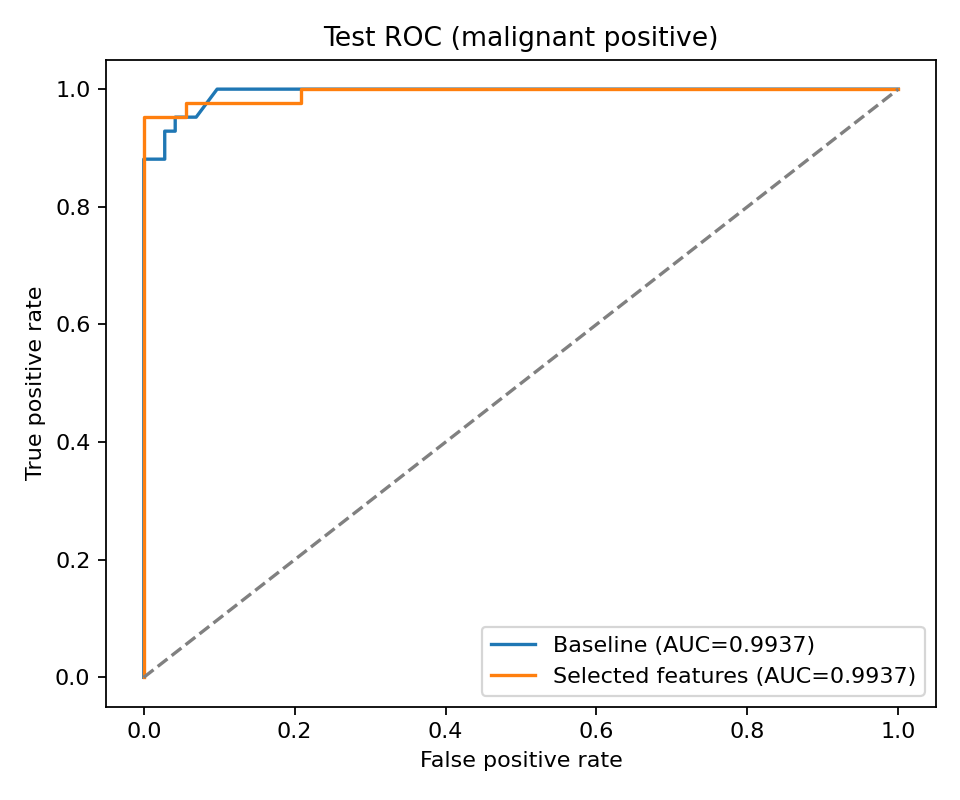

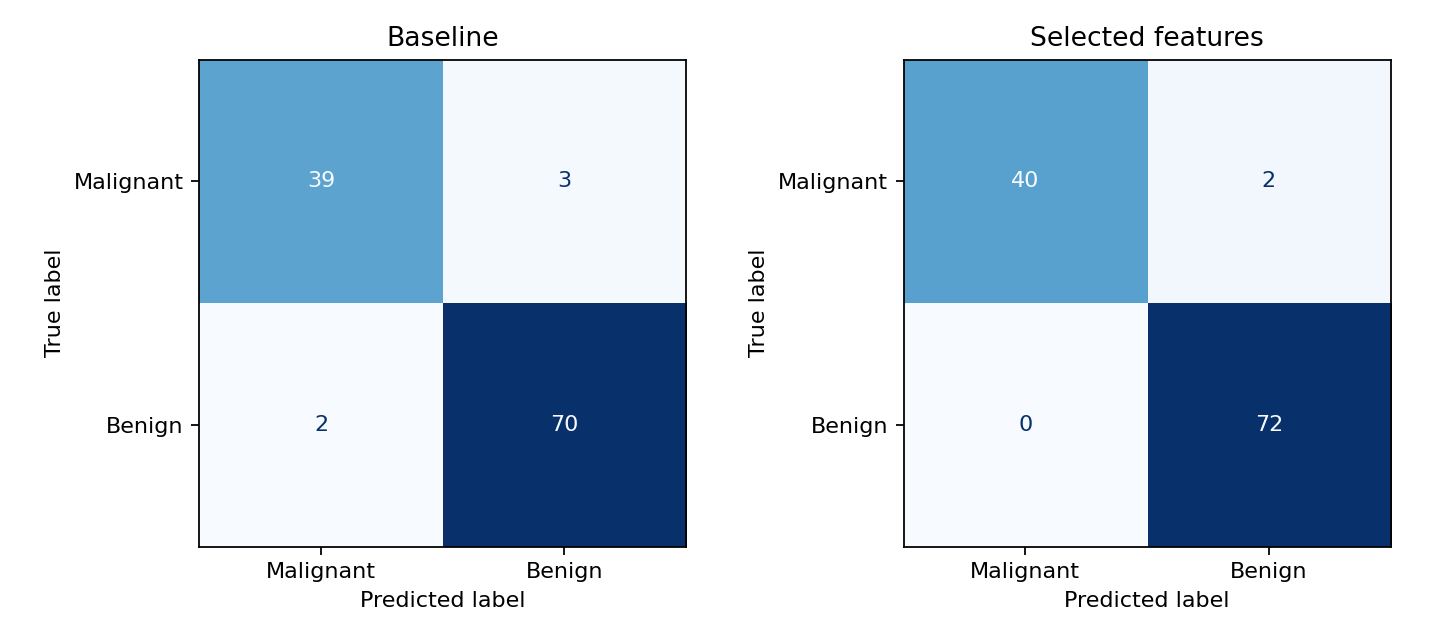

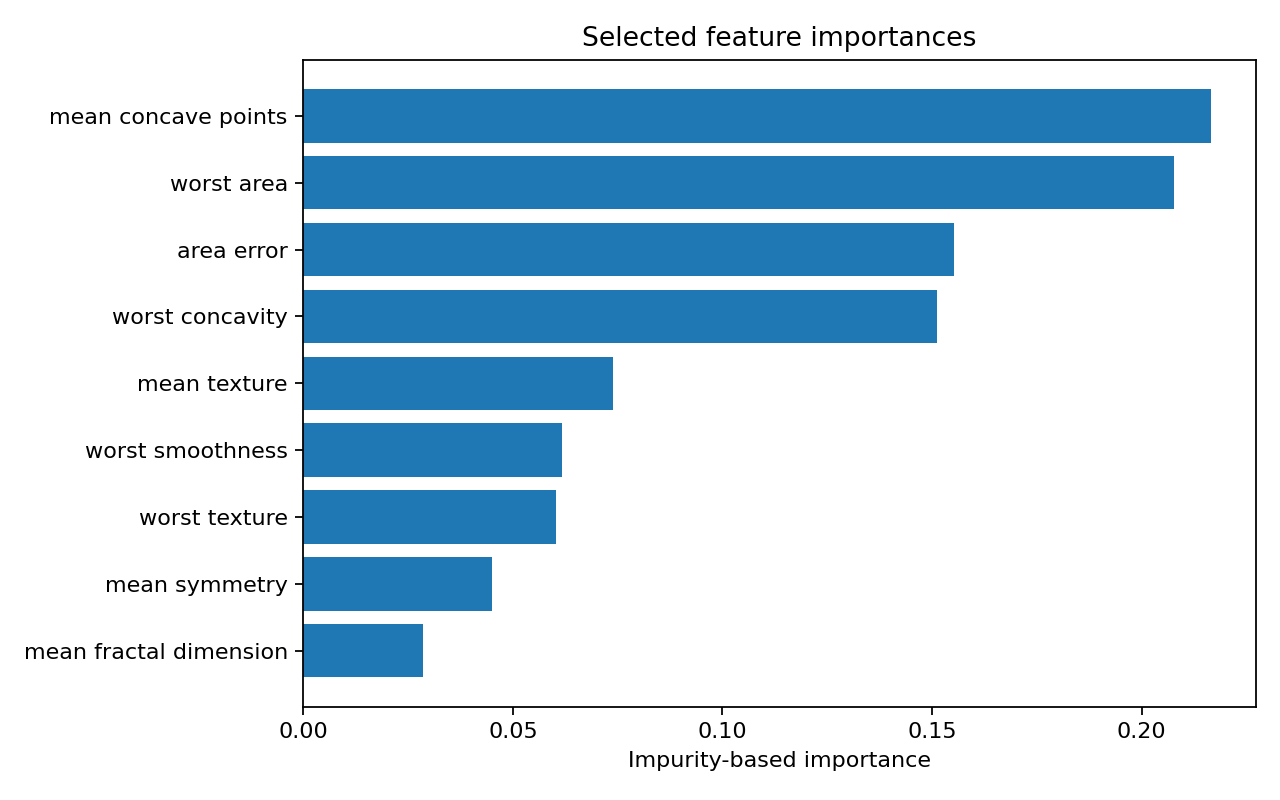

In [4]:
for name in ("roc.png", "confusion_matrices.png", "feature_importances.png"):
    display(Image(filename=str(Path("results") / name)))

## Optional fresh search
A full search is expensive. Set the flag to True only to run a new training-only GA experiment. Results are saved separately.

In [5]:
RUN_FRESH_SEARCH = False
if RUN_FRESH_SEARCH:
    fresh = run(search=True, population=50, generations=20, jobs=2, out="results/search")

## Interpretation and limitations
The replay verifies the reported accuracy on the original split, not independent generalization. ROC-AUC is unchanged. The gain combines feature selection and hyperparameter tuning. A full fresh search and independent evaluation remain future work. This project is educational and not a medical diagnostic system.